**Quantum entanglement.**
Two qubits are **entangled** when their joint state cannot be written as a
tensor product of individual qubit states:
$|\psi\rangle \neq |\phi_0\rangle \otimes |\phi_1\rangle$.
Measuring one qubit instantly determines the outcome of measuring the other,
regardless of the distance between them.

The standard recipe for creating a two-qubit entangled state (a **Bell state**)
is to apply a Hadamard to one qubit followed by a CNOT:

$$I \otimes H\;|00\rangle = |0\rangle|{+}\rangle
\xrightarrow{\text{CNOT}}
\frac{1}{\sqrt{2}}(|00\rangle + |11\rangle) = |\Phi^+\rangle$$

The resulting $|\Phi^+\rangle$ state has no individual qubit description:
both outcomes (00 and 11) occur with equal probability and
the results are always perfectly correlated.

---
A single `AerSimulator` backend is shared across all cells.

In [1]:
"""entanglement.ipynb"""

# Cell 01 - Imports and shared AerSimulator backend

import numpy as np
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import (
    plot_bloch_multivector,
    plot_distribution,
    plot_state_qsphere,
)
from qiskit_aer import AerSimulator

from qis101_utils import as_latex

backend = AerSimulator()
print(f"Backend name    : {backend.name}")
print(f"Aer version     : {backend.configuration().backend_version}")
print(f"Max qubits      : {backend.configuration().n_qubits}")
print(f"Max shots       : {backend.configuration().max_shots:,}")
print(f"Simulation type : {backend.configuration().simulator}")
methods = backend.available_methods()
if methods:
    print("Available methods:")
    for method in methods:
        print(f"  {method}")

Backend name    : aer_simulator
Aer version     : 0.17.2
Max qubits      : 30
Max shots       : 1,000,000
Simulation type : True
Available methods:
  automatic
  statevector
  density_matrix
  stabilizer
  matrix_product_state
  extended_stabilizer
  unitary
  superop


---
**Cell 02 - Two qubits, NOT entangled.**
Only qubit 0 receives a Hadamard; qubit 1 stays in $|0\rangle$.
The joint state after H is $|0\rangle|{+}\rangle = (|00\rangle + |01\rangle)/\sqrt{2}$,
which factors as a tensor product - the qubits are independent.
Measurement gives outcomes `00` and `01` with equal probability;
qubit 1 is always 0 regardless of what qubit 0 gives.

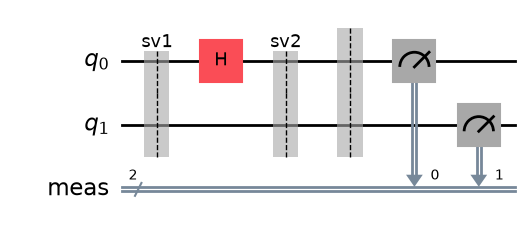

<IPython.core.display.Math object>

<IPython.core.display.Math object>

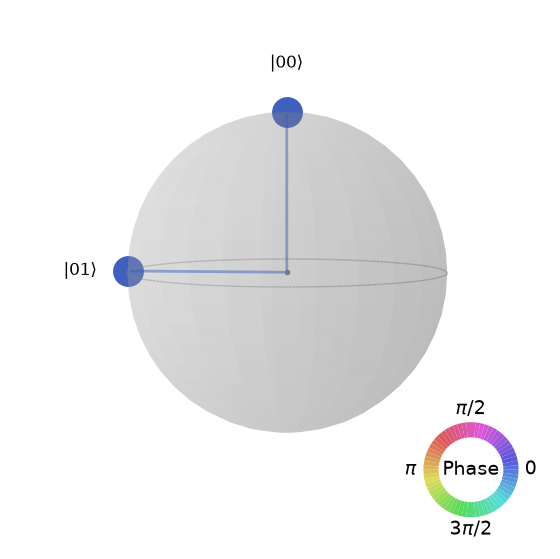

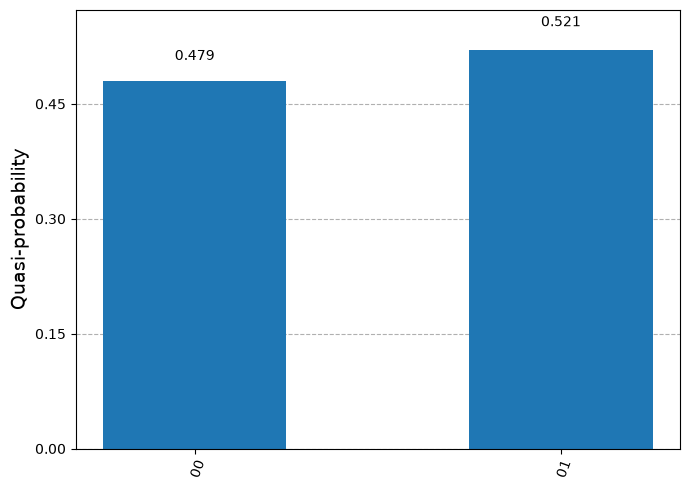

In [2]:
# Cell 02 - Two qubits NOT entangled: H on q0 only
# Joint state: |0>|+> = (|00>+|01>)/sqrt2  (separable - not entangled)
# Outcomes: '00' and '01' each ~50%

qc = QuantumCircuit(2)
qc.save_statevector("sv1")
qc.h(0)
qc.save_statevector("sv2")
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(transpile(qc, backend)).result()
sv1 = result.data(0)["sv1"]
sv2 = result.data(0)["sv2"]

display(as_latex(sv1, prefix=r"\mathbf{Statevector\;1}="))
display(as_latex(sv2, prefix=r"\mathbf{Statevector\;2}="))
display(plot_state_qsphere(sv2))
display(plot_distribution(result.get_counts(qc)))

---
**Cell 03 - Two qubits ENTANGLED: the $|\Phi^+\rangle$ Bell state.**
Adding a CNOT after the Hadamard entangles the two qubits:

$$|00\rangle
\xrightarrow{I\otimes H}
\frac{|00\rangle+|01\rangle}{\sqrt{2}}
\xrightarrow{\text{CNOT}_{0\to1}}
\frac{|00\rangle+|11\rangle}{\sqrt{2}} = |\Phi^+\rangle$$

The `qsphere` visualization shows two antipodal blobs of equal size,
reflecting equal probability for `00` and `11` with perfect correlation:
measuring qubit 0 as 0 forces qubit 1 to be 0, and vice versa.

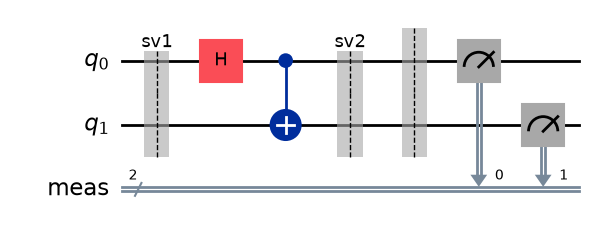

<IPython.core.display.Math object>

<IPython.core.display.Math object>

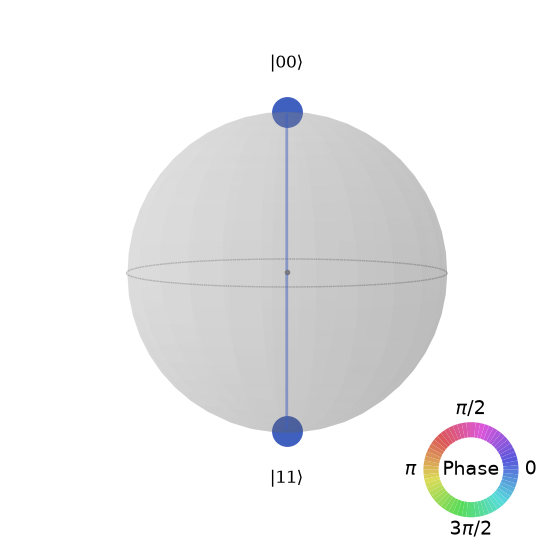

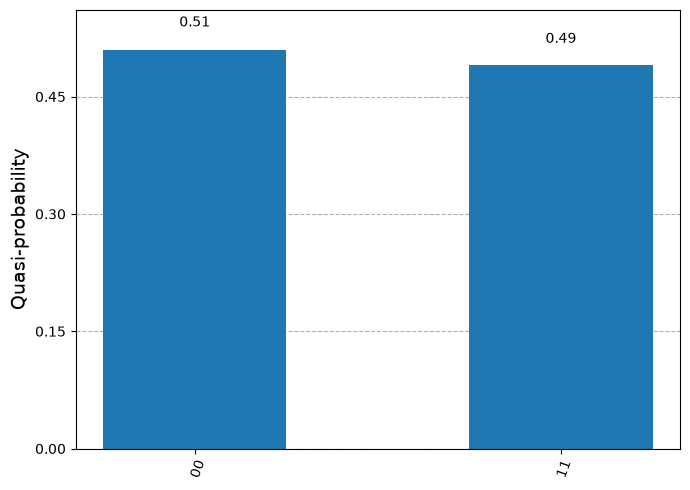

In [3]:
# Cell 03 - Two qubits ENTANGLED

qc = QuantumCircuit(2)
qc.save_statevector("sv1")
qc.h(0)
qc.cx(0, 1)
qc.save_statevector("sv2")
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(transpile(qc, backend)).result()
sv1 = result.data(0)["sv1"]
sv2 = result.data(0)["sv2"]

display(as_latex(sv1, prefix=r"\mathbf{Statevector\;1}="))
display(as_latex(sv2, prefix=r"\mathbf{Statevector\;2}="))
display(plot_state_qsphere(sv2))
display(plot_distribution(result.get_counts(qc)))

---
**Cell 04 - Same Bell state with 10,000 shots.**
With more shots the 50/50 split between `00` and `11` converges clearly,
and outcomes `01` and `11` are confirmed to be absent.

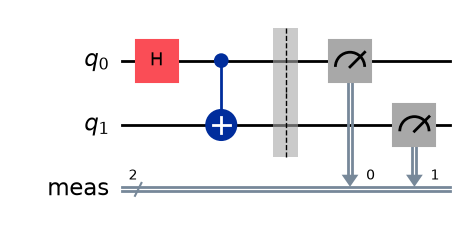

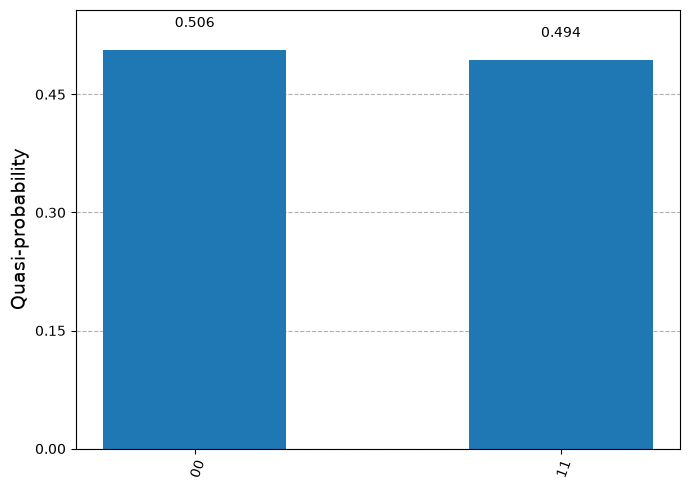

In [4]:
# Cell 04 - Two qubits ENTANGLED (use 10,000 shots)

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(transpile(qc, backend), shots=10_000).result()
display(plot_distribution(result.get_counts(qc)))

---
**Cell 05 - Three qubits, NOT entangled.**
The Hadamard gates applied to qubits 0 and 1 independently; qubit 2 stays in $|0\rangle$.
The joint state factors as
$|{+}\rangle \otimes |{+}\rangle \otimes |0\rangle$.
All four outcomes `000`, `010`, `100`, `110` occur with equal probability (~25%);
qubit 2 is always 0.

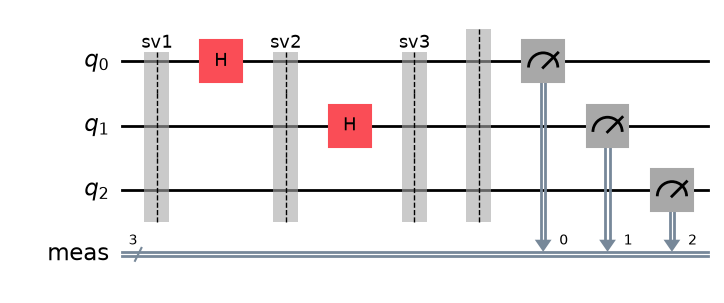

<IPython.core.display.Math object>

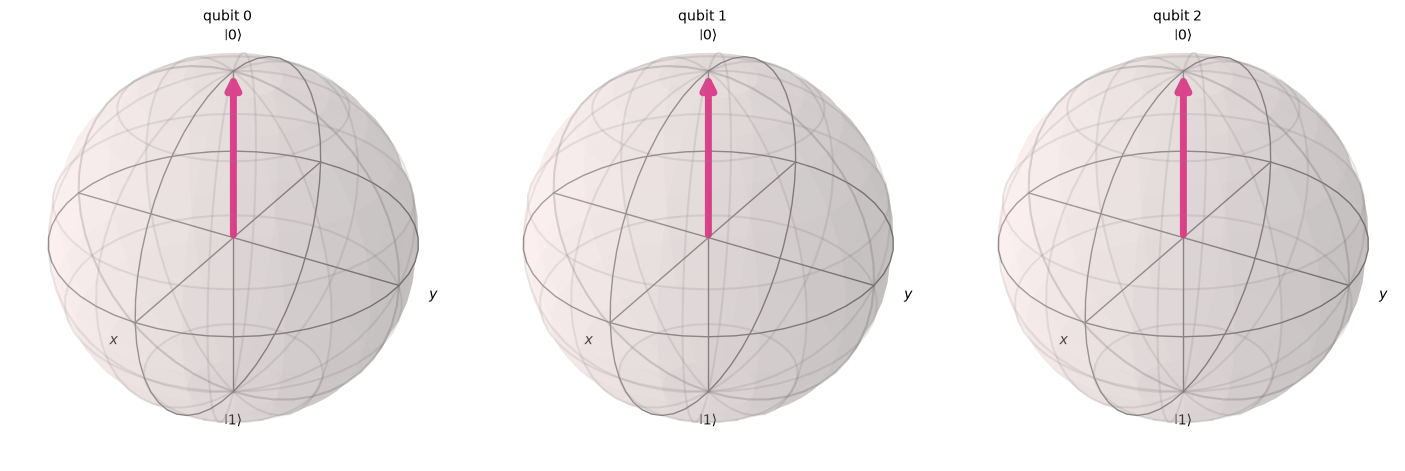

<IPython.core.display.Math object>

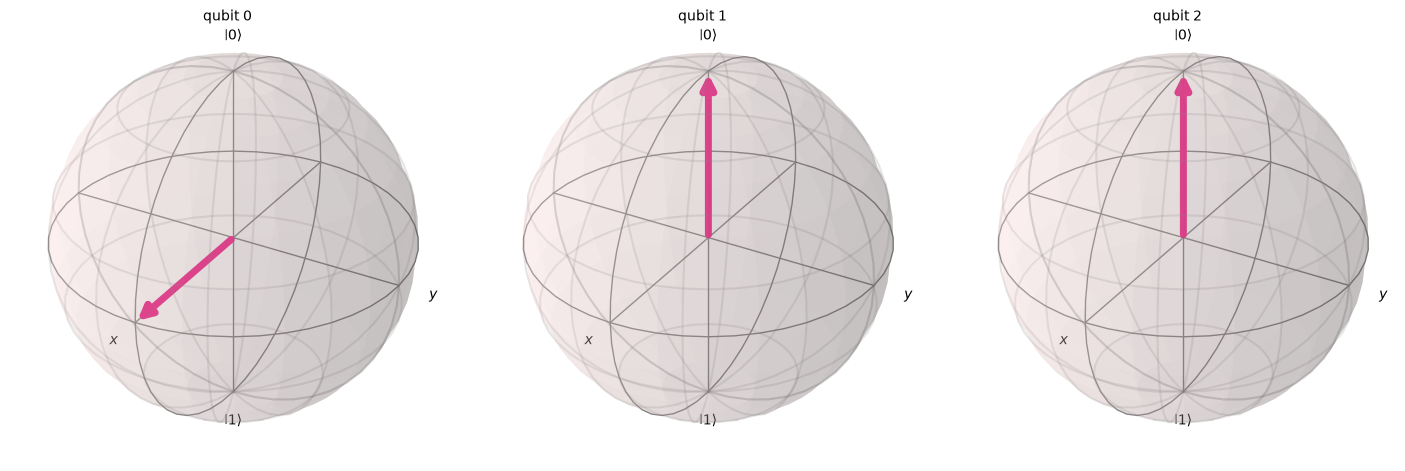

<IPython.core.display.Math object>

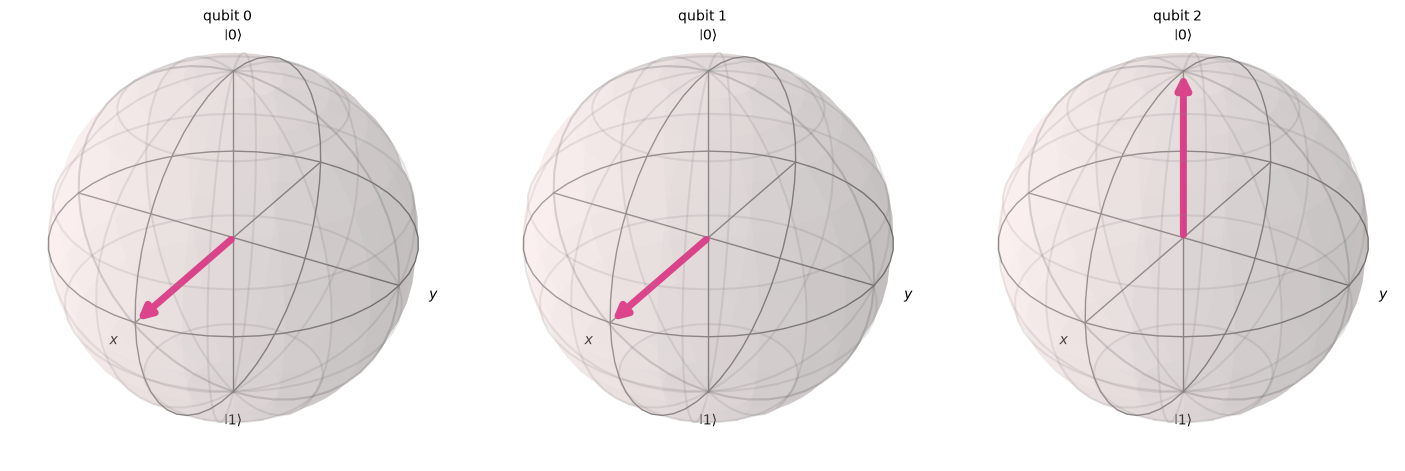

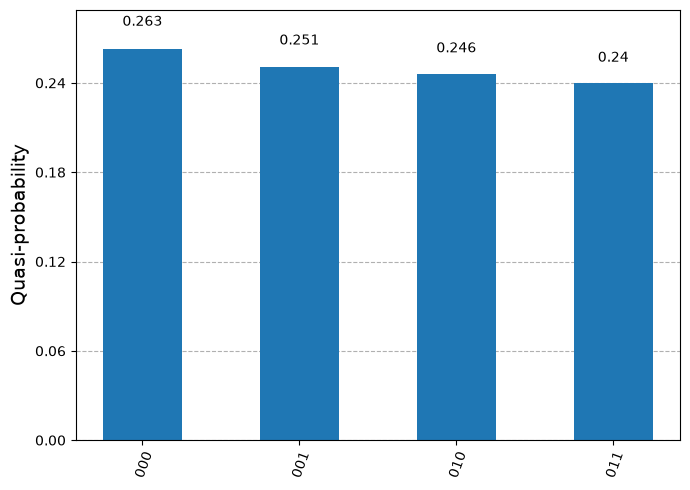

In [5]:
# Cell 05 - Three qubits NOT entangled

qc = QuantumCircuit(3)
qc.save_statevector("sv1")
qc.h(0)
qc.save_statevector("sv2")
qc.h(1)
qc.save_statevector("sv3")
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(transpile(qc, backend)).result()
sv1 = result.data(0)["sv1"]
sv2 = result.data(0)["sv2"]
sv3 = result.data(0)["sv3"]

display(as_latex(sv1, prefix=r"\mathbf{Statevector\;1}="))
display(plot_bloch_multivector(sv1))
display(as_latex(sv2, prefix=r"\mathbf{Statevector\;2}="))
display(plot_bloch_multivector(sv2))
display(as_latex(sv3, prefix=r"\mathbf{Statevector\;3}="))
display(plot_bloch_multivector(sv3))
display(plot_distribution(result.get_counts(qc)))

---
**Cell 06 - Same three-qubit separable state with 1,000,000 shots.**
With one million shots the four outcomes converge tightly to 25% each,
providing a high-precision confirmation of the Born rule probabilities.

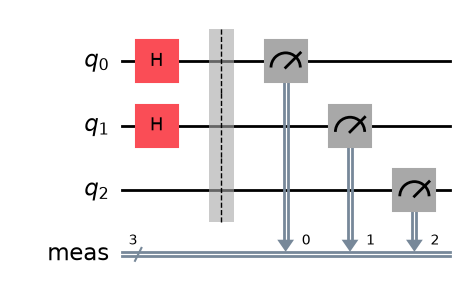

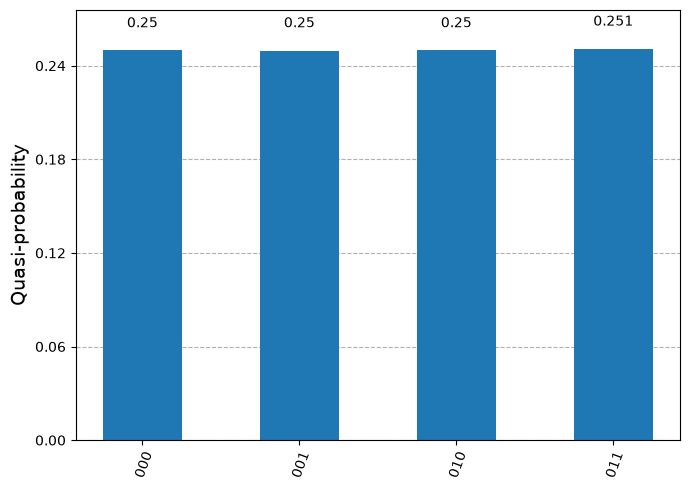

In [6]:
# Cell 06 - Three qubits NOT entangled (1M shots)

qc = QuantumCircuit(3)
qc.h(0)
qc.h(1)
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(transpile(qc, backend), shots=1_000_000).result()
display(plot_distribution(result.get_counts(qc)))

---
**Cell 07 - Three qubits ENTANGLED via CNOT and SWAP.**
A Hadamard on q0 and q1 followed by a CNOT from q0 to q2 introduces
entanglement between q0 and q2.
The SWAP of q1 and q2 then redistributes the entanglement.
The resulting distribution is no longer uniform across all four originally
accessible outcomes - the correlations imposed by entanglement change which
outcomes can occur.

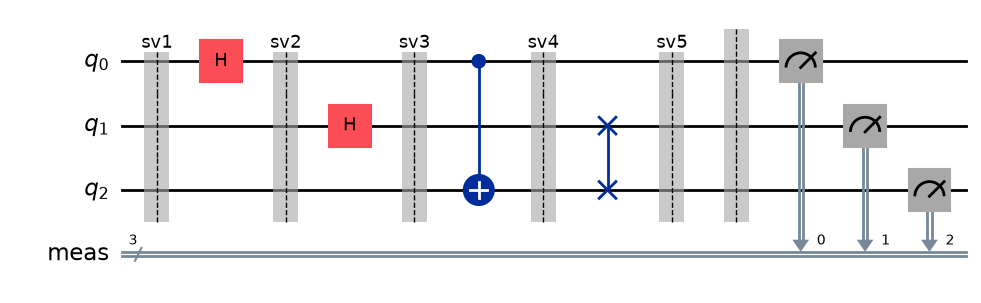

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

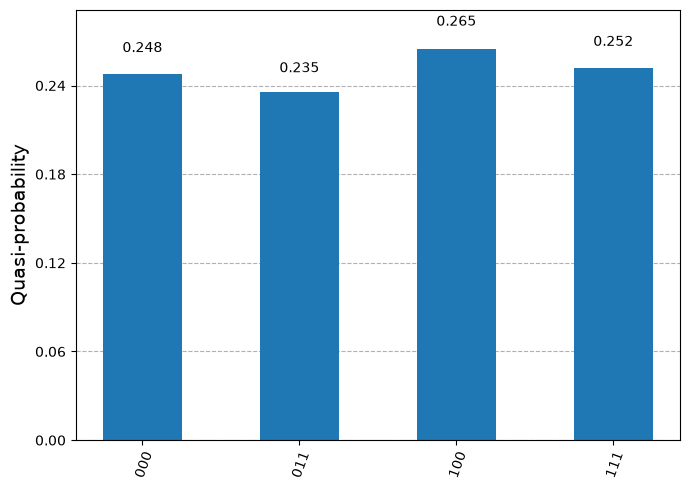

In [7]:
# Cell 07 - Three qubits ENTANGLED

qc = QuantumCircuit(3)
qc.save_statevector("sv1")
qc.h(0)
qc.save_statevector("sv2")
qc.h(1)
qc.save_statevector("sv3")
qc.cx(0, 2)
qc.save_statevector("sv4")
qc.swap(1, 2)
qc.save_statevector("sv5")
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(transpile(qc, backend, optimization_level=1)).result()
sv1 = result.data(0)["sv1"]
sv2 = result.data(0)["sv2"]
sv3 = result.data(0)["sv3"]
sv4 = result.data(0)["sv4"]
sv5 = result.data(0)["sv5"]

display(as_latex(sv1, prefix=r"\mathbf{Statevector\;1}="))
display(as_latex(sv2, prefix=r"\mathbf{Statevector\;2}="))
display(as_latex(sv3, prefix=r"\mathbf{Statevector\;3}="))
display(as_latex(sv4, prefix=r"\mathbf{Statevector\;4}="))
display(as_latex(sv5, prefix=r"\mathbf{Statevector\;5}="))
display(plot_distribution(result.get_counts(qc)))

---
**Cell 08 - Same entangled circuit with 100,000 shots.**

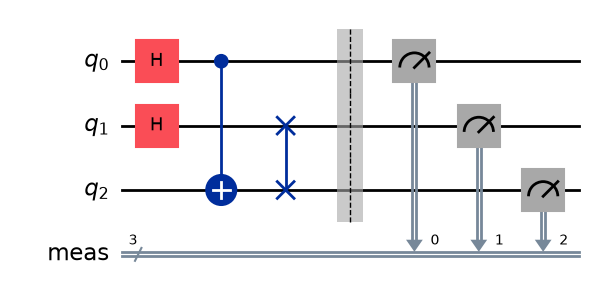

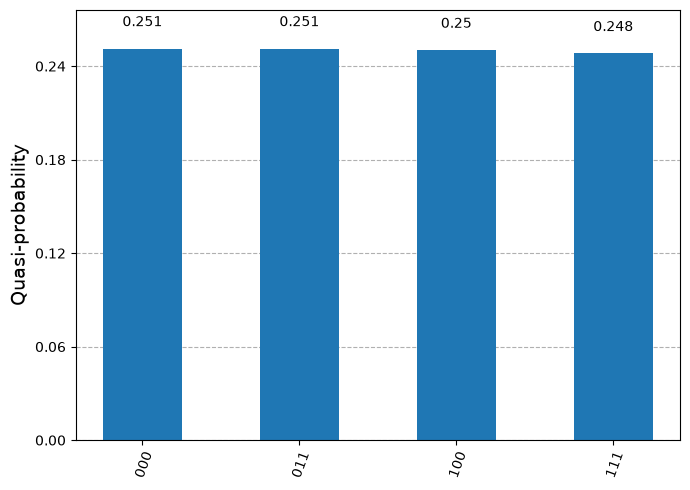

In [8]:
# Cell 08 - Three-qubit ENTANGLED (100,000 shots)

qc = QuantumCircuit(3)
qc.h(0)
qc.h(1)
qc.cx(0, 2)
qc.swap(1, 2)
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(
    transpile(qc, backend, optimization_level=1), shots=100_000
).result()
display(plot_distribution(result.get_counts(qc)))

---
**Cell 09 - The Greenberger-Horne-Zeilinger (GHZ) state.**
The GHZ state is the three-qubit generalization of the Bell state:

$$|\text{GHZ}\rangle = \frac{|000\rangle + |111\rangle}{\sqrt{2}}$$

It is prepared by a Hadamard on qubit 0 followed by two cascaded CNOTs:
$\text{CNOT}_{0\to1}$ then $\text{CNOT}_{1\to2}$.
Only outcomes `000` and `111` occur - all three qubits are perfectly correlated.
The GHZ state is maximally entangled: no qubit has an individual state
on the Bloch sphere, which is why `plot_bloch_multivector` would show
all three qubit vectors at the origin.

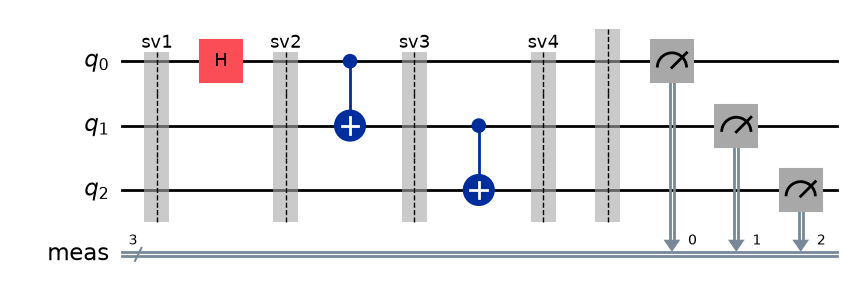

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

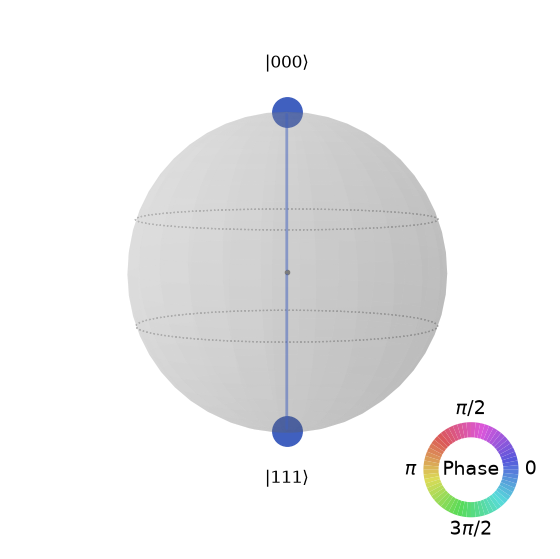

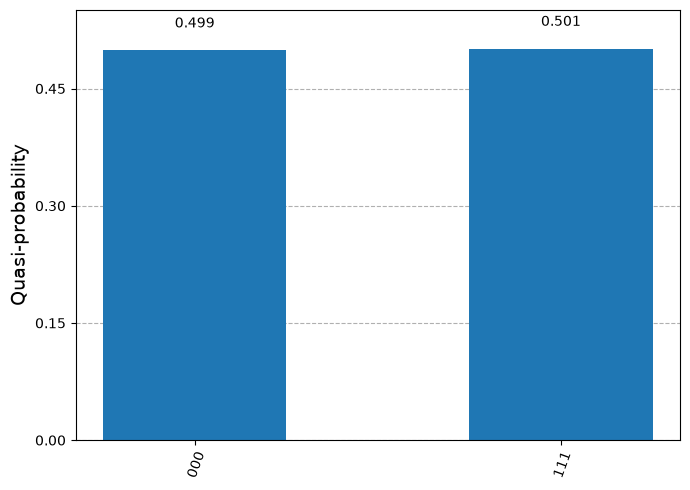

In [9]:
# Cell 09 - Greenberger-Horne-Zeilinger (GHZ)

qc = QuantumCircuit(3)
qc.save_statevector("sv1")
qc.h(0)
qc.save_statevector("sv2")
qc.cx(0, 1)
qc.save_statevector("sv3")
qc.cx(1, 2)
qc.save_statevector("sv4")
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(transpile(qc, backend), shots=100_000).result()
sv1 = result.data(0)["sv1"]
sv2 = result.data(0)["sv2"]
sv3 = result.data(0)["sv3"]
sv4 = result.data(0)["sv4"]

display(as_latex(sv1, prefix=r"\mathbf{Statevector\;1}="))
display(as_latex(sv2, prefix=r"\mathbf{Statevector\;2}="))
display(as_latex(sv3, prefix=r"\mathbf{Statevector\;3}="))
display(as_latex(sv4, prefix=r"\mathbf{Statevector\;4}="))
display(plot_state_qsphere(sv4))
display(plot_distribution(result.get_counts(qc)))

---
**Cell 10 - The W state (Wolfgang Dür, 2000).**
The W state is a fundamentally different class of three-qubit entanglement:

$$|W\rangle = \frac{|001\rangle + |010\rangle + |100\rangle}{\sqrt{3}}$$

Unlike GHZ, the W state is **robust**: if one qubit is lost, the remaining
two are still entangled.
Measurement outcomes `001`, `010`, `100` each occur with probability $1/3$.

The circuit uses $R_y\!\left(2\arccos\!\tfrac{1}{\sqrt{3}}\right)$ on qubit 0
to set $\alpha = 1/\sqrt{3}$ and $\beta = \sqrt{2/3}$,
then a controlled-H, two CNOTs, and an X gate redistribute the amplitude
equally across the three single-excitation states.

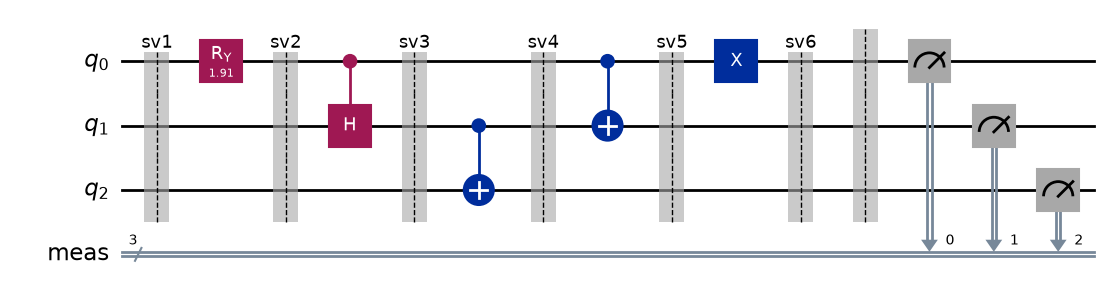

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

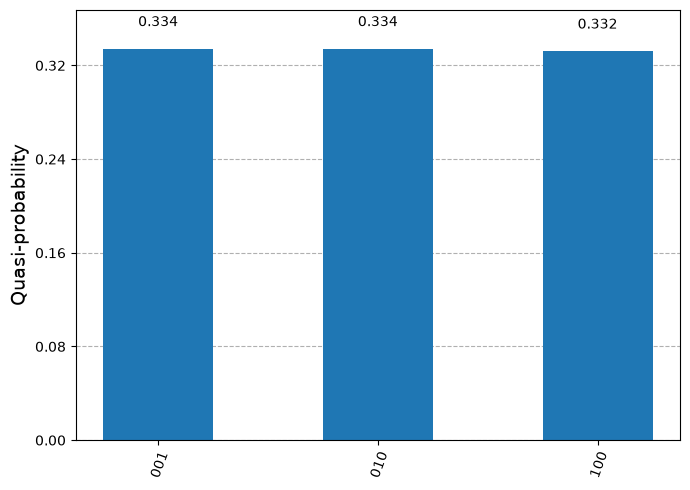

In [10]:
# Cell 10 - Wolfgang Dur (W)
# state (100,000 shots)

qc = QuantumCircuit(3)
qc.save_statevector("sv1")
qc.ry(2 * np.arccos(1 / np.sqrt(3)), 0)
qc.save_statevector("sv2")
qc.ch(0, 1)
qc.save_statevector("sv3")
qc.cx(1, 2)
qc.save_statevector("sv4")
qc.cx(0, 1)
qc.save_statevector("sv5")
qc.x(0)
qc.save_statevector("sv6")
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(transpile(qc, backend), shots=100_000).result()
sv1 = result.data(0)["sv1"]
sv2 = result.data(0)["sv2"]
sv3 = result.data(0)["sv3"]
sv4 = result.data(0)["sv4"]
sv5 = result.data(0)["sv5"]
sv6 = result.data(0)["sv6"]

display(as_latex(sv1, prefix=r"\mathbf{Statevector\;1}="))
display(as_latex(sv2, prefix=r"\mathbf{Statevector\;2}="))
display(as_latex(sv3, prefix=r"\mathbf{Statevector\;3}="))
display(as_latex(sv4, prefix=r"\mathbf{Statevector\;4}="))
display(as_latex(sv5, prefix=r"\mathbf{Statevector\;5}="))
display(as_latex(sv6, prefix=r"\mathbf{Statevector\;6}="))
display(plot_distribution(result.get_counts(qc)))

---
**Cell 11 - Hadamard applied after entanglement.**
Both qubits are initialized to $|0\rangle$, so the system starts in
the two-qubit computational basis state $|00\rangle = |q_1{=}0\rangle|q_0{=}0\rangle$.

**sv1 - After H applied to q0:**
The Hadamard acts on q0 alone, leaving q1 in $|0\rangle$:

$$|q_1{=}0\rangle \otimes H|q_0{=}0\rangle
= |0\rangle \otimes \frac{|0\rangle + |1\rangle}{\sqrt{2}}
= \frac{1}{\sqrt{2}}(|00\rangle + |01\rangle)$$

This is a **separable** (not entangled) state: q0 is in superposition,
q1 is still definitely $|0\rangle$, and the two qubits have no correlation.

**sv2 - Bell state after CNOT:**
The CNOT gate has q0 as control and q1 as target.
It flips q1 whenever q0 is $|1\rangle$ and leaves q1 alone when q0 is $|0\rangle$:

$$\frac{1}{\sqrt{2}}(|00\rangle + |01\rangle)
\xrightarrow{\text{CNOT}_{q0 \to q1}}
\frac{1}{\sqrt{2}}(|00\rangle + |11\rangle) = |\Phi^+\rangle$$

This is a **Bell state** - the qubits are now entangled 
Only outcomes `00` and `11` can occur; they are perfectly correlated (maximally entangled). 

**sv3 - After H applied to q0 only:**
$H$ acts on q0 while q1 is unchanged.
Using $H|0\rangle = \frac{|0\rangle+|1\rangle}{\sqrt{2}}$ and $H|1\rangle = \frac{|0\rangle-|1\rangle}{\sqrt{2}}$:

$$\frac{1}{\sqrt{2}}\left(|0\rangle\frac{|0\rangle+|1\rangle}{\sqrt{2}} + |1\rangle\frac{|0\rangle-|1\rangle}{\sqrt{2}}\right) = \frac{1}{2}(|00\rangle + |10\rangle + |01\rangle - |11\rangle)$$

The **negative amplitude on $|11\rangle$** comes from the minus sign in $H|1\rangle$:
the q0 component $-|1\rangle$ combines with q1 in $|1\rangle$ to give $-|11\rangle$.
The qsphere shows this as a phase-$\pi$ blob (gold) at $|11\rangle$
while the other three states have phase 0 (blue).

**sv4 - After H applied to q1:**

Start from sv3, grouping terms by the value of q1:

$$\frac{1}{2}(|00\rangle + |01\rangle) + \frac{1}{2}(|10\rangle - |11\rangle)$$

Factor out the q1 state from each group:

$$\frac{1}{2}|q_1{=}0\rangle(|0\rangle + |1\rangle) + \frac{1}{2}|q_1{=}1\rangle(|0\rangle - |1\rangle)$$

Now apply $H$ to q1 only. Replace each q1 ket using $H|0\rangle = \frac{|0\rangle+|1\rangle}{\sqrt{2}}$ and $H|1\rangle = \frac{|0\rangle-|1\rangle}{\sqrt{2}}$:

$$\frac{1}{2}\cdot\frac{|0\rangle+|1\rangle}{\sqrt{2}}\cdot(|0\rangle+|1\rangle)
\;+\;
\frac{1}{2}\cdot\frac{|0\rangle-|1\rangle}{\sqrt{2}}\cdot(|0\rangle-|1\rangle)$$

Multiply out the first product $(|0\rangle+|1\rangle)(|0\rangle+|1\rangle)$:

$$|00\rangle + |01\rangle + |10\rangle + |11\rangle$$

Multiply out the second product $(|0\rangle-|1\rangle)(|0\rangle-|1\rangle)$:

$$|00\rangle - |01\rangle - |10\rangle + |11\rangle$$

Add the two results:

$$|00\rangle + |01\rangle + |10\rangle + |11\rangle
\;+\;
|00\rangle - |01\rangle - |10\rangle + |11\rangle
= 2|00\rangle + 2|11\rangle$$

The $|01\rangle$ and $|10\rangle$ terms cancel exactly.
Collecting the overall factor of $\frac{1}{2\sqrt{2}}$:

$$\frac{1}{2\sqrt{2}} \cdot 2(|00\rangle + |11\rangle)
= \frac{1}{\sqrt{2}}(|00\rangle + |11\rangle) = |\Phi^+\rangle$$

The Bell state is restored exactly.
This reveals that $|\Phi^+\rangle$ is an **eigenstate** of $H\otimes H$ with eigenvalue $+1$:
the two Hadamard gates leave it completely unchanged.
Measurement therefore still shows only `00` and `11` with equal probability,
identical to measuring the Bell state directly without the trailing Hadamard gates.

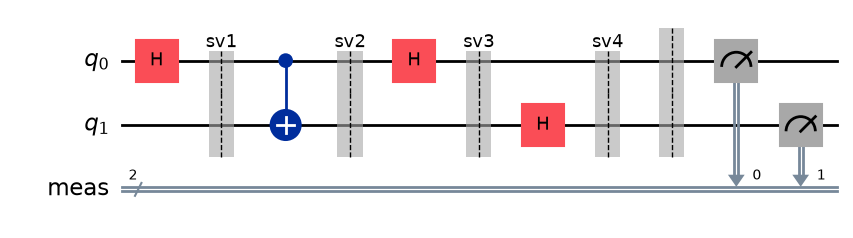

<IPython.core.display.Math object>

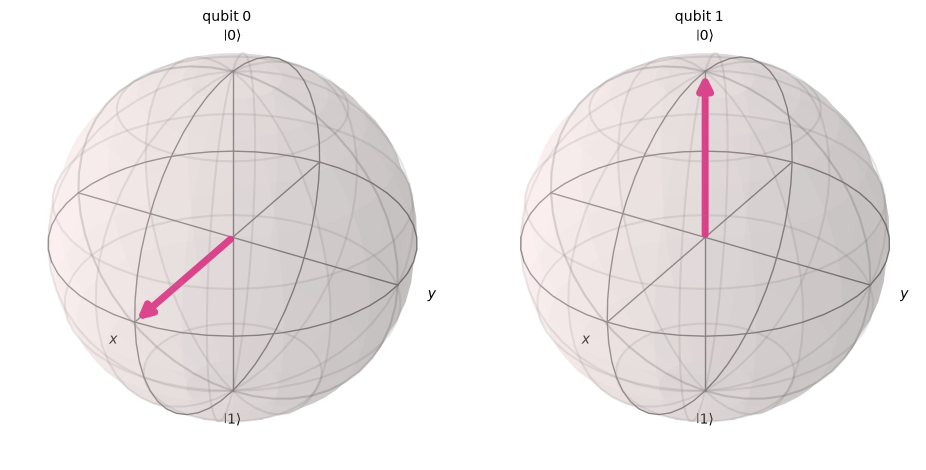

<IPython.core.display.Math object>

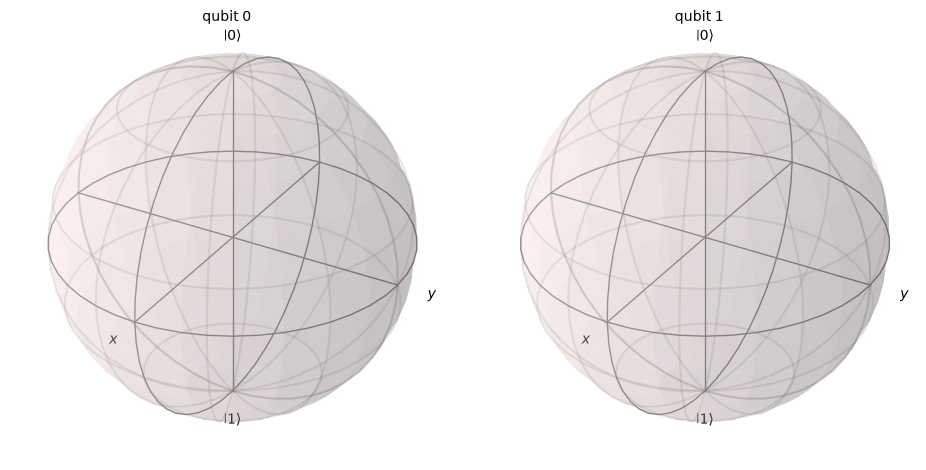

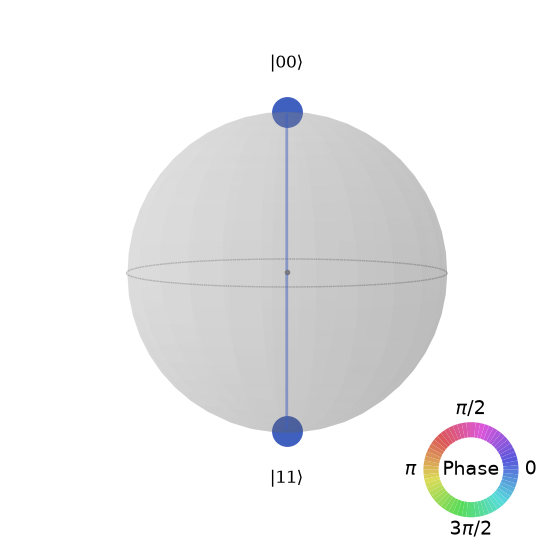

<IPython.core.display.Math object>

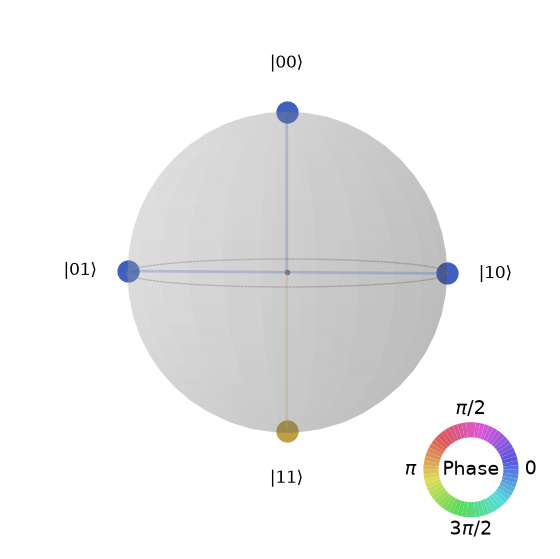

<IPython.core.display.Math object>

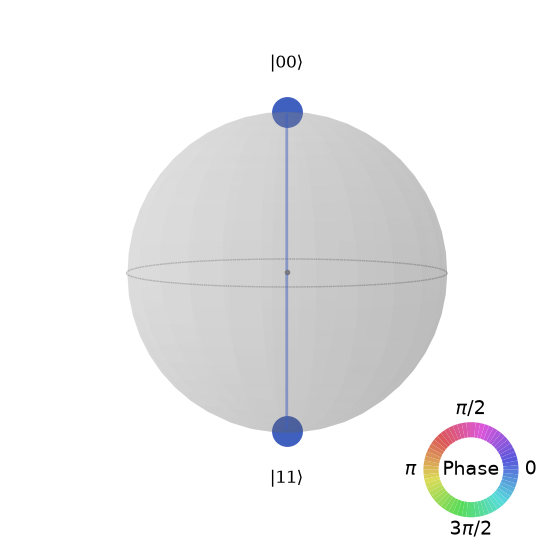

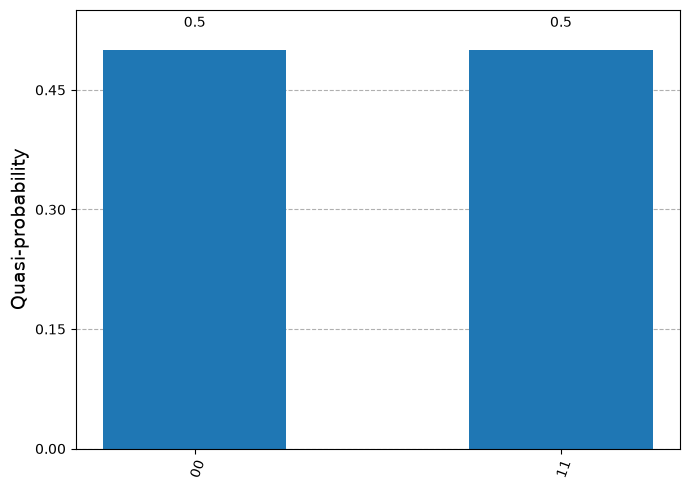

In [11]:
# Cell 11 - Hadamard after entanglement
# (100,000 shots)

qc = QuantumCircuit(2)
qc.h(0)
qc.save_statevector("sv1")
qc.cx(0, 1)
qc.save_statevector("sv2")
qc.h(0)
qc.save_statevector("sv3")
qc.h(1)
qc.save_statevector("sv4")
qc.measure_all()

display(qc.draw(output="mpl"))

result = backend.run(transpile(qc, backend), shots=100_000).result()
sv1 = result.data(0)["sv1"]
sv2 = result.data(0)["sv2"]
sv3 = result.data(0)["sv3"]
sv4 = result.data(0)["sv4"]

display(as_latex(sv1, prefix=r"\mathbf{Statevector\;1}="))
display(plot_bloch_multivector(sv1))
display(as_latex(sv2, prefix=r"\mathbf{Statevector\;2}="))
display(plot_bloch_multivector(sv2))
display(plot_state_qsphere(sv2))
display(as_latex(sv3, prefix=r"\mathbf{Statevector\;3}="))
display(plot_state_qsphere(sv3))
display(as_latex(sv4, prefix=r"\mathbf{Statevector\;4}="))
display(plot_state_qsphere(sv4))
display(plot_distribution(result.get_counts(qc)))